## Classification algorithims
## Logistic regression

## Objectives
- Difference between classifications and regression
- Sigmoid Function
- Logistic regression example.
- How to read a classification report,

Regression predicts a number - eg house price etc
Classification predicts a category

1. Is this email spam or not? -Binary classification (2 classes)
2. Is this benign, malingant or borderlines? Multi-class classification
3. Is this photo a cat, a dog or a bird? Multi-class classification

In [2]:
# Load the breast cancer wisconsin dataset  
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

# separate features and target
X = data.data
y = data.target

In [3]:
data.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [4]:
# spilt into training and testing sets

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [22]:
# import standard scaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# fit scaler on training data and transform both training and testing data
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [6]:
# Train a logistic regression model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [ ]:
# Evaluate the model

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1] # pick everything where row is all and column is 1

# [:, 1] means we want to select all rows and only the second column (index 1) which contains the probabilities for the positive class (malignant)
print(f'Sample predicted classes: {y_pred[:5]}')
print(f'Sample predicted probabilities: {y_prob[:5].round(3)}')

Sample predicted classes: [1 0 0 1 1]
Sample predicted probabilities: [0.886 0.    0.003 0.999 1.   ]


# K-Nearest Neighbours
## Learning Objectives:
1. Explain the KNN algorithims
2. Understand how K controls the bias variance trade off
3. Implement KNN and find optimal K using a validation curve.

# What the KNN is and how it works?
1. choose the number of neighbours K
2. For each new unlabelled point, calculate its distance to every training point.
3. Identify the K-training points that are closest (Euclidean distancr by default)
4. The majority class among those K neighbours is the prediction
5. For regression, take the average of the K neighbours instead


# Choosing the right K
# K too small eg K = 1
Very sensitive to noise in the data.
Overfitting: near perfevt on training but poor on test.

# K too large K = 100
Includes neighbours that are far away and irrelevant.
Underfitting: Misses local patterns.
Both training and test accuracy are low.

## Practical rule:
Start with K = square root of number of training samples. Then test values around that using a
validation curve and pick the K with the best test accuracy.

In [ ]:
# load data
from sklearn.datasets import load_iris
iris = load_iris()

In [ ]:
# spilt into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=6) 

In [6]:
# scale the data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler() # create an instance of the StandardScaler class
X_train = scaler.fit_transform(X_train) # fit the scaler on the training data and transform it
X_test = scaler.transform(X_test) # transform the testing data using the same scaler (do not fit the X-test just transform it)

In [9]:
# Finding the best k value for KNN (K-accuracy for k = 1 to 20)
train_accuracy, test_accuracy = [], []

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# for loop to find the best k value for KNN
for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)     # create an instance of the KNN classifier with the current k value
    knn.fit(X_train, y_train)         # fit the model on the training data
    train_accuracy.append(accuracy_score(y_train, knn.predict(X_train)))   # calculate and append the training accuracy for the current k value  
    test_accuracy.append(accuracy_score(y_test, knn.predict(X_test)))     # calculate and append the testing accuracy for the current k value

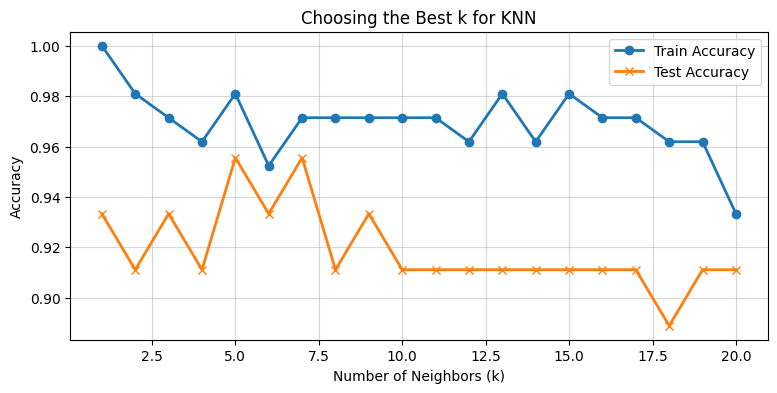

In [12]:
# Interpretting results/plotting results
from matplotlib import pyplot as plt

plt.figure(figsize=(9, 4))
plt.plot(range(1, 21), train_accuracy, label='Train Accuracy', marker='o', linewidth=2)
plt.plot(range(1, 21), test_accuracy, label='Test Accuracy', marker='x', linewidth=2)
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy') 
plt.title('Choosing the Best k for KNN')  
plt.legend()     # add a legend to the plot to differentiate between training and testing accuracy lines
plt.grid(alpha=0.5)   # add grid lines to the plot (alpha=0.5 makes the grid lines lighter, true = default and adds grid lines to the plot)
plt.show()       # display the plot




In [15]:
best_k = test_accuracy.index(max(test_accuracy)) + 1
print(f'Best k value: {best_k} with Test Accuracy: {max(test_accuracy):.2f}')

Best k value: 5 with Test Accuracy: 0.96


In [16]:
# Train the KNN model with the best k value

knn_final = KNeighborsClassifier(n_neighbors=best_k)     # create an instance of the KNN classifier with the best k value
knn_final.fit(X_train, y_train)         # fit the model on the training data

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


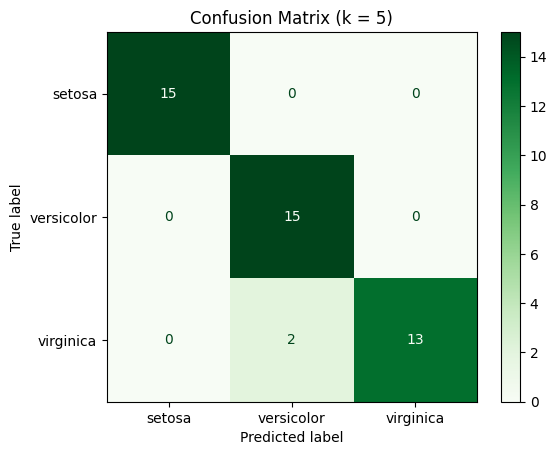

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(knn_final, X_test, y_test, display_labels=iris.target_names, cmap='Greens')
plt.title(f'Confusion Matrix (k = {best_k})')
plt.show()


In [18]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

# Evaluation deep dive
## ROC curve and  AUC score.
Tools for evaluating the diagnostic ability of a binary classifier (esp when you have an imbalanced dataset or
want to see how the model behaves at different sensitivity levels).

In [19]:
# Importing 
from sklearn.metrics import RocCurveDisplay
from sklearn.datasets import load_breast_cancer

In [ ]:
# Loading Data
data = load_breast_cancer()

# separate features and target
X = data.data
y = data.target

In [ ]:
# splitting data into training and testing sets
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
            X, y, test_size=0.2, random_state=42)


In [24]:
from sklearn.preprocessing import StandardScaler
 
scaler = StandardScaler()
 
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [26]:
# Train a logistic regression model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000).fit(X_train, y_train) 

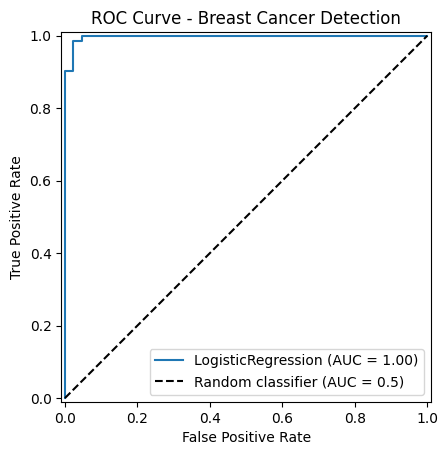

In [ ]:
RocCurveDisplay.from_estimator(model, X_test, y_test)   
plt.plot([0, 1], [0, 1], 'k--', label = 'Random classifier (AUC = 0.5)') # add a dashed diagonal line representing a random classifier (AUC = 0.5) for reference  
# AUC = area under the curve, the higher the AUC the better the model's performance in distinguishing between the classes

plt.title('ROC Curve - Breast Cancer Detection')
plt.xlabel('False Positive Rate')   
plt.ylabel('True Positive Rate')
plt.legend() 
plt.show()


# Understanding the ROC curve
The curve plots the tradeoff between ```true positive rate``` and the 
```false positive rate``` across every possible decision threshold.

TPR = TP/ (TP + FN) -> How many actual positives did we catch?

FPR = FP (FP + TN) -> How many negatives did we incorrectly flag as positive?


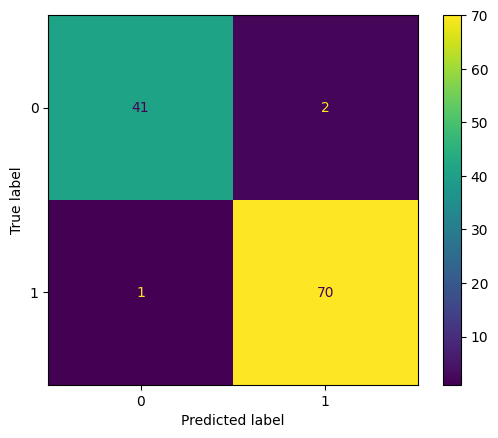

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
 
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
 
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

In [29]:
# Checking for accuracy, precision, recall and f1-score
from sklearn.metrics import classification_report, accuracy_score
print(classification_report(y_test, y_pred))
print(f'Accuracy: {accuracy_score(y_test, y_pred):.2f}')


              precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

Accuracy: 0.97


# Interpreting AUC scores
1.0 -> Perfect.
0.90 - 0.99 -> Excellent.
0.80 - 0.89 -> Good.
0.70 - 0.79 -> Fair.
0.50 -> Fail.